# Parte 1. K-Means con 2 variables
Problema: una empresa quiere identificar distintos perfiles de clientes según su comportamiento de compra.

Las variables serán:
- Frecuencia de compras: número de compras realizadas al año.
- Gasto total anual: dinero gastado durante el año.
 
Utilizaremos datos sintéticos, sin etiquetas previas, para descubrir tres grupos de clientes.

# Bloque 1. Importar librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Bloque 2. Generar los datos
Crearemos 600 clientes distribuidos alrededor de tres perfiles de comportamiento.

In [2]:
X, _ = make_blobs(
    n_samples=600,
    centers=[
        [25, 25],
        [48, 75],
        [80, 40]
    ],
    cluster_std=[5, 7, 9],
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Frecuencia_compras", "Gasto_anual"]
)

df.head()

,Frecuencia_compras,Gasto_anual
0,26.120462,25.062962
1,79.823260,44.972410
2,20.908897,35.461936
3,87.072201,43.829118
4,46.257251,81.800997


# Bloque 3. Visualizar los datos originales

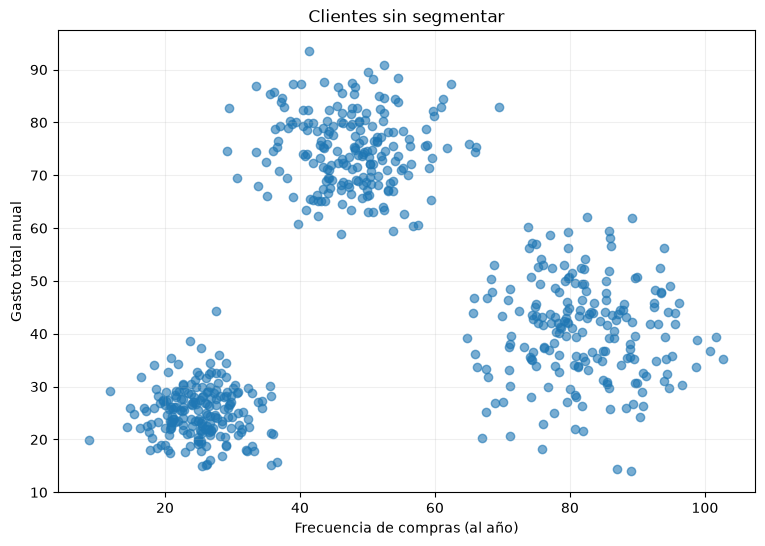

In [3]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Frecuencia_compras"],
    df["Gasto_anual"],
    alpha=0.6
)

plt.xlabel("Frecuencia de compras (al año)")
plt.ylabel("Gasto total anual")
plt.title("Clientes sin segmentar")
plt.grid(alpha=0.2)
plt.show()

# Bloque 4. Estandarizar las variables
K-Means utiliza distancias, por lo que es importante que las variables tengan escalas comparables.

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print(X_scaled[:5])

[[-1.04227153 -0.9898009 ]
 [ 1.16601881 -0.08660073]
 [-1.25657416 -0.51804721]
 [ 1.46409952 -0.13846661]
 [-0.21423504  1.58414307]]


En este ejercicio exploratorio no hay conjunto de test. Si posteriormente quisiéramos evaluar el modelo sobre datos separados, ajustaríamos el escalador únicamente con los datos de entrenamiento.

# Bloque 5. Entrenar K-Means
Indicamos que queremos encontrar tres clústeres.

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df.head()

,Frecuencia_compras,Gasto_anual,Cluster
0,26.120462,25.062962,1
1,79.823260,44.972410,0
2,20.908897,35.461936,1
3,87.072201,43.829118,0
4,46.257251,81.800997,2


K-Means realiza iterativamente dos operaciones:
1. Asigna cada cliente al centroide más cercano.
2. Recalcula los centroides utilizando la media de los puntos asignados.
Repite el proceso hasta alcanzar la convergencia o el límite de iteraciones.

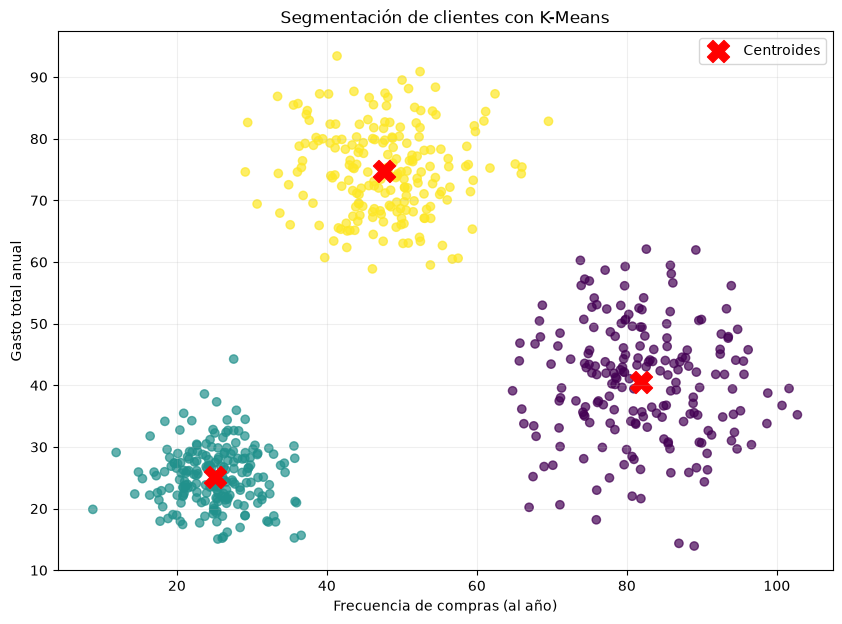

In [6]:
centroides = scaler.inverse_transform( ################################## TRANSFORMADA INVERSA
    kmeans.cluster_centers_
)

plt.figure(figsize=(10, 7))

plt.scatter(
    df["Frecuencia_compras"],
    df["Gasto_anual"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c="red",
    marker="X",
    s=250,
    label="Centroides"
)

plt.xlabel("Frecuencia de compras (al año)")
plt.ylabel("Gasto total anual")
plt.title("Segmentación de clientes con K-Means")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Los colores identifican los grupos descubiertos por el algoritmo. Las cruces rojas representan sus centroides.

A diferencia de la imagen original, aquí no dibujamos contornos irregulares: K-Means divide el espacio según la distancia a los centroides.

# Bloque 7. Analizar los resultadosmm

In [7]:
resumen = df.groupby("Cluster").agg(
    Clientes=("Cluster", "size"),
    Frecuencia_media=("Frecuencia_compras", "mean"),
    Gasto_medio=("Gasto_anual", "mean")
)

print(resumen.round(2))

         Clientes  Frecuencia_media  Gasto_medio
Cluster                                         
0             199             81.92        40.46
1             200             25.03        25.19
2             201             47.62        74.82


Con esta información podemos interpretar los grupos como clientes poco frecuentes, clientes de gasto elevado o clientes que compran frecuentemente pero gastan menos por compra.

Los números de clúster son arbitrarios: el clúster 0 no representa necesariamente al grupo de menor gasto.

# Bloque 8. Evaluar el modelo
Calculamos el coeficiente de silueta.
Su interpretación general:

- Cercano a 1: clústeres compactos y bien separados.
- Cercano a 0: clústeres solapados.
- Negativo: algunos puntos podrían estar mejor asignados a otro clúster.

In [9]:
score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.749


# Bloque 9. Elegir el número de clústeres

Hasta ahora hemos fijado k=3. Podemos comparar varios valores.

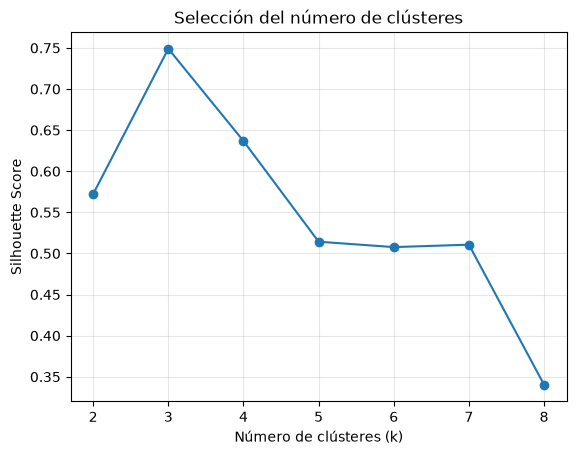

In [10]:
valores_k = range(2, 9)
scores = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    scores.append(
        silhouette_score(X_scaled, etiquetas)
    )

plt.plot(valores_k, scores, marker="o")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silhouette Score")
plt.title("Selección del número de clústeres")
plt.grid(alpha=0.3)
plt.show()

El valor con mayor puntuación es un candidato razonable, aunque también debemos valorar si la segmentación tiene sentido para el negocio.

# Parte 2. K-Means con 3 variables
Ahora añadiremos una tercera variable: antigüedad del cliente, medida en años.

El objetivo será segmentar clientes considerando simultáneamente frecuencia de compras, gasto anual y antigüedad.

# Bloque 10. Generar datos con tres variables

In [19]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Tres perfiles de clientes
perfiles = [
    (25, 250, 2),    # Compras bajas, gasto bajo, nuevos
    (48, 750, 8),    # Compras medias, gasto alto, veteranos
    (80, 400, 5)     # Compras altas, gasto medio
]

datos = []

for frecuencia, gasto, antiguedad in perfiles:

    for _ in range(200):
        datos.append([
            max(0, round(rng.normal(frecuencia, 7))),
            max(0, round(rng.normal(gasto, 100), 2)),
            np.clip(rng.normal(antiguedad, 1.5), 0, 15)
        ])

df3 = pd.DataFrame(
    datos,
    columns=[
        "Frecuencia_compras",
        "Gasto_anual",
        "Antiguedad"
    ]
)

# Mezclar los registros
df3 = df3.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

df3.head()

,Frecuencia_compras,Gasto_anual,Antiguedad
0,36,313.75,0.951604
1,80,573.96,4.276651
2,83,353.42,8.561910
3,21,281.56,3.808780
4,24,224.66,1.761223


# Bloque 11. Estandarizar y entrenar
El procedimiento es prácticamente idéntico al anterior.

In [20]:
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(df3)

kmeans3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df3["Cluster"] = kmeans3.fit_predict(X3_scaled)

La diferencia es que ahora K-Means calcula distancias en un espacio de tres dimensiones.

# Bloque 12. Visualizar los resultados en 3D

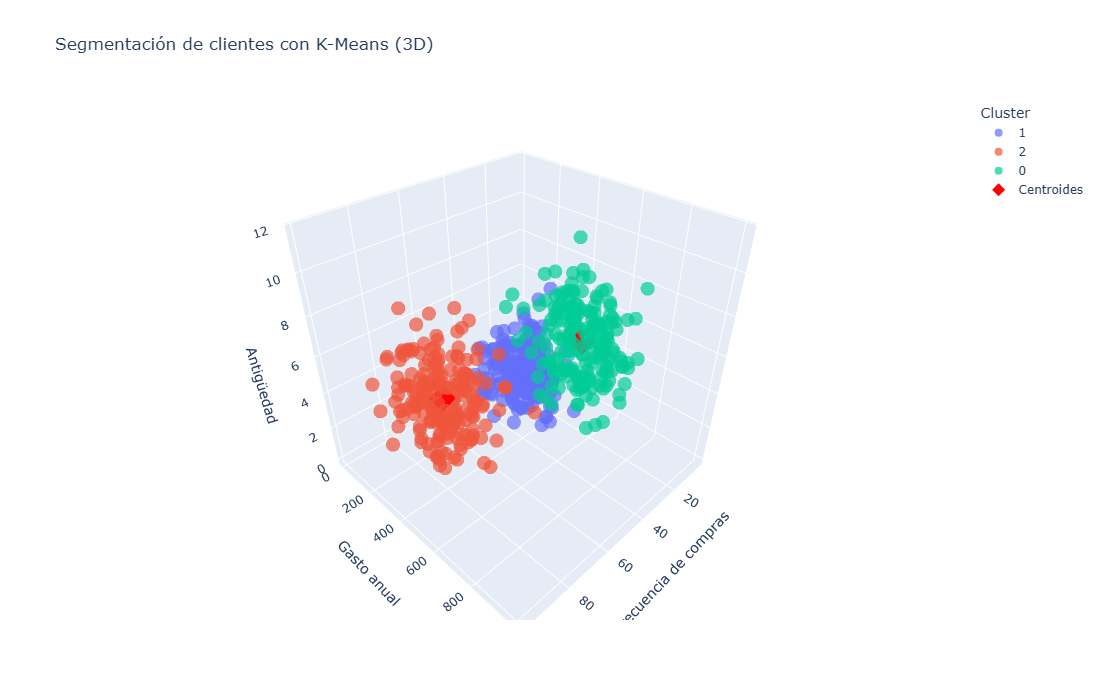

In [21]:
# Bloque 12. Visualización 3D interactiva

import plotly.express as px
import plotly.graph_objects as go

# Gráfico de los clientes
fig = px.scatter_3d(
    df3,
    x="Frecuencia_compras",
    y="Gasto_anual",
    z="Antiguedad",
    color=df3["Cluster"].astype(str),
    opacity=0.7,
    title="Segmentación de clientes con K-Means (3D)",
    labels={"color": "Cluster"}
)

# Recuperar los centroides en las unidades originales
centros3 = scaler3.inverse_transform(
    kmeans3.cluster_centers_
)

# Añadir los centroides
fig.add_trace(
    go.Scatter3d(
        x=centros3[:, 0],
        y=centros3[:, 1],
        z=centros3[:, 2],
        mode="markers",
        marker=dict(
            size=10,
            color="red",
            symbol="diamond"
        ),
        name="Centroides"
    )
)

# Configuración visual
fig.update_layout(
    width=950,
    height=700,
    scene=dict(
        xaxis_title="Frecuencia de compras",
        yaxis_title="Gasto anual",
        zaxis_title="Antigüedad"
    )
)

fig.show()

# Bloque 13. Interpretar y evaluar

In [17]:
resumen3 = df3.groupby("Cluster").agg(
    Clientes=("Cluster", "size"),
    Frecuencia_media=("Frecuencia_compras", "mean"),
    Gasto_medio=("Gasto_anual", "mean"),
    Antiguedad_media=("Antiguedad", "mean")
)

print(resumen3.round(2))

score3 = silhouette_score(
    X3_scaled,
    df3["Cluster"]
)

print("Silhouette Score 3D:", round(score3, 3))

         Clientes  Frecuencia_media  Gasto_medio  Antiguedad_media
Cluster                                                           
0             200             48.23        75.25              8.33
1             200             25.12        24.71              2.09
2             200             80.90        39.89              5.02
Silhouette Score 3D: 0.648
